# **Exercice 2 : Classification d'images (Fashion-MNIST)**

Dans cet exercice, nous allons passer à un niveau supérieur en manipulant un jeu de données de vêtements (Fashion-MNIST), en comparant différentes fonctions d'activation, puis en construisant un **Réseau de Neurones Convolutif (CNN)** et en appliquant de la **Data Augmentation**.

## **Introduction et Chargement du dataset**

Le dataset **Fashion-MNIST** contient 70 000 images en niveaux de gris ($28 \times 28$ pixels) réparties en 10 classes de vêtements (T-shirt, pantalon, pull, robe, manteau, sandale, chemise, basket, sac, bottine).

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Pour la reproductibilité
tf.random.set_seed(42)

# Chargement du dataset[cite: 15]
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


# Étape 1 : Exploration du jeu de données

On vérifie les dimensions des tableaux d'entraînement et de test, et on visualise un échantillon d'images pour observer la nature des données[cite: 15].

Dimensions du train set: (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)


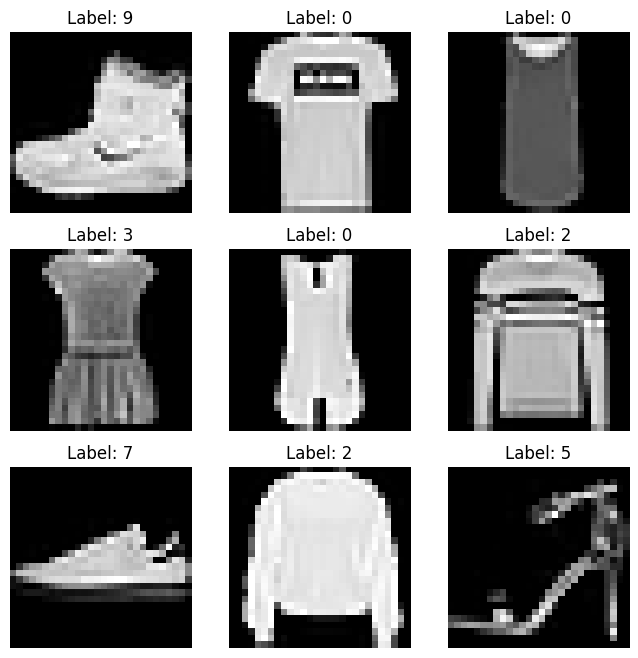

In [3]:
print("Dimensions du train set:", X_train.shape)
print("Dimensions du test set :", X_test.shape)

# Visualisation d'exemples
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

### **Question :**         

**Que remarquez-vous sur la nature des données et la taille des images ?**

Les images sont en niveaux de gris avec une résolution de $28 \times 28$ pixels. Contrairement au dataset MNIST (chiffres), il s'agit ici d'articles vestimentaires (vêtements, chaussures, accessoires) répartis en 10 classes distinctes. Les formes sont plus complexes et variées que de simples chiffres manuscrits.

# Étape 2 : Prétraitement des données

*   Mise à l’échelle des pixels entre 0 et 1
*   Conversion en float
*   Encodage des labels



In [4]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

### **Questions :**

**1.Pourquoi faut-il normaliser les images ?**

La normalisation (division par 255.0) permet de ramener les valeurs des pixels de l'intervalle $[0, 255]$ à l'intervalle $[0, 1]$. Cela évite la saturation des fonctions d'activation, stabilise les calculs et accélère considérablement la convergence de l'optimiseur (Adam).

**2.Quelle est l'importance du one-hot encoding dans un problème de classification multiclasse ?**

L'encodage one-hot transforme les étiquettes entières (ex: classe 3) en vecteurs binaires (ex: `[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]`). Il est indispensable pour être compatible avec la fonction de perte `categorical_crossentropy`, qui compare des probabilités de sortie à des vecteurs cibles.

# Étape 3 : Création d'un modèle dense (ANN) avec Dropout

`Dropout(0.2)` : Désactive aléatoirement 20% des neurones pendant l'entraînement pour éviter le surapprentissage (overfitting).

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model_ann = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_ann.summary()

# Compilation et entraînement[cite: 17]
model_ann.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_ann = model_ann.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7841 - loss: 0.6149 - val_accuracy: 0.8387 - val_loss: 0.4414
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8480 - loss: 0.4230 - val_accuracy: 0.8497 - val_loss: 0.4057
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8602 - loss: 0.3837 - val_accuracy: 0.8607 - val_loss: 0.3767
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8696 - loss: 0.3578 - val_accuracy: 0.8640 - val_loss: 0.3660
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8763 - loss: 0.3385 - val_accuracy: 0.8687 - val_loss: 0.3505
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8787 - loss: 0.3252 - val_accuracy: 0.8744 - val_loss: 0.3495
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8847 - loss: 0.3138 - val_accuracy: 0.8747 - val_loss: 0.3400
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8867 - loss: 0.3042 - val_accuracy: 0.

### **Questions :**

**1. Pourquoi utilise-t-on la fonction d'activation ReLU ici ?**

La fonction ReLU (Rectified Linear Unit) est utilisée dans les couches cachées car elle introduit de la non-linéarité, permettant au réseau d'apprendre des motifs complexes tout en évitant le problème de la disparition du gradient (vanishing gradient).

**2. Quelle est la différence entre `accuracy` et `val_accuracy` ?**

L'`accuracy` mesure la précision du modèle sur le jeu d'entraînement (train), tandis que la `val_accuracy` mesure sa précision sur le jeu de validation (validation), c'est-à-dire des données qu'il n'utilise pas pour apprendre mais pour évaluer sa généralisation.

**3. Que se passe-t-il si l'on augmente le nombre d'époques à 50 ?**

Le modèle risque de faire du surapprentissage (*overfitting*) : la précision sur l'entraînement continuera d'augmenter, mais la précision de validation stagnera ou commencera à diminuer, car le modèle mémorisera les images par cœur au lieu de généraliser.


# Étape 4 : Introduction aux Fonctions d'Activation

On compare ici l'impact de différentes fonctions d'activation (``sigmoid``, ``tanh``, ``relu`` et ``LeakyReLU``) sur les performances du réseau.

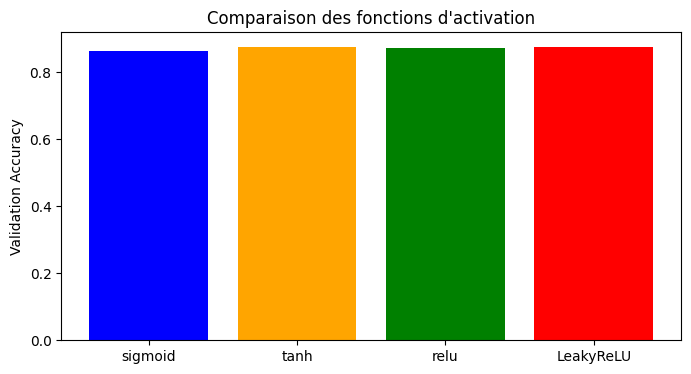

In [6]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

# LeakyReLU
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h_leaky = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h_leaky.history['val_accuracy'][-1]

# Visualisation comparative
plt.figure(figsize=(8, 4))
plt.bar(results.keys(), results.values(), color=['blue', 'orange', 'green', 'red'])
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.show()

### **Questions :**

**1. Quelle fonction d'activation donne les meilleurs résultats ?**

En général, **ReLU** (ou son variante **LeakyReLU**) offre les meilleures performances en termes de vitesse de convergence et de précision par rapport à ``sigmoid`` ou ``tanh``.

**2. Pourquoi les fonctions sigmoïde et tanh sont moins utilisées dans les couches cachées ?**

Elles souffrent du problème de l'atténuation du gradient (*vanishing gradient*), où les gradients deviennent extrêmement faibles sur les couches profondes, bloquant l'apprentissage du réseau.

**3. À quoi sert LeakyReLU ?**

``LeakyReLU`` permet d'éviter le problème des "neurones morts" propres à ReLU en autorisant une petite pente non nulle (ex: $0.1$) pour les valeurs négatives, ce qui maintient le flux du gradient.

# Étape 5 : Modèle CNN (Convolutional Neural Network)

Contrairement aux réseaux denses (ANN), les **CNN** utilisent des couches de convolution (``Conv2D``) et de max-pooling (``MaxPooling2D``) pour extraire automatiquement les caractéristiques spatiales (formes, contours) des images.

In [7]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Reshape pour ajouter la dimension "canal" (images en niveaux de gris = 1 canal)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

# Entraînement du CNN[cite: 19]
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

# Évaluation
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set:", test_acc)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step - accuracy: 0.7634 - loss: 0.6498 - val_accuracy: 0.8544 - val_loss: 0.4181
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 59ms/step - accuracy: 0.8527 - loss: 0.4128 - val_accuracy: 0.8691 - val_loss: 0.3627
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.8690 - loss: 0.3584 - val_accuracy: 0.8827 - val_loss: 0.3226
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.8819 - loss: 0.3238 - val_accuracy: 0.8886 - val_loss: 0.3038
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 60ms/step - accuracy: 0.8907 - loss: 0.2984 - val_accuracy: 0.8892 - val_loss: 0.3027
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 60ms/step - accuracy: 0.8980 - loss: 0.2775 - val_accuracy: 0.8903 - val_loss: 0.2939
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 61ms/step - accuracy: 0.9044 - loss: 0.2624 - val_accuracy: 0.9022 - val_loss: 0.2669
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 59ms/step - accuracy: 0.9079 - loss: 0.2481 - 

### **Questions :**

**1. Quelle est la différence entre un ANN et un CNN ?**

Un ANN (réseau dense) aplatit l'image en un vecteur 1D et traite chaque pixel indépendamment, perdant la structure spatiale. Un CNN utilise des filtres de convolution (``Conv2D``) pour extraire automatiquement les caractéristiques spatiales locales (bords, textures, formes) et des couches de *pooling* pour réduire la dimensionnalité.

**2. Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?**

Parce qu'il est spécifiquement conçu pour le traitement d'images grâce à l'invariance par translation et à la préservation de la structure spatiale bidimensionnelle.

**3. Quel est le rôle des couches de Pooling ?**

Les couches de *MaxPooling* réduisent la taille spatiale des cartes de caractéristiques (*feature maps*), ce qui diminue le nombre de paramètres, réduit le coût de calcul et limite le surapprentissage.

# Étape 6 : Visualisation des performances (Matrice de confusion)



313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


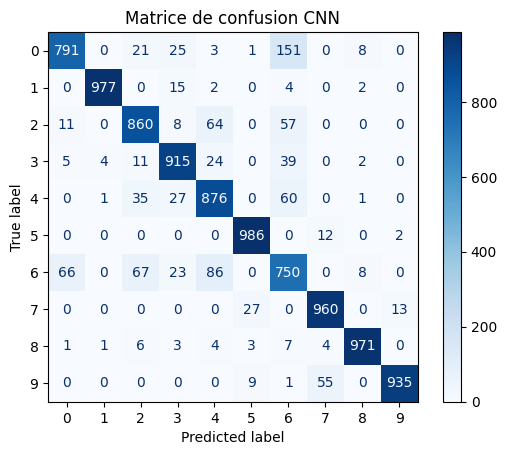

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matrice de confusion CNN")
plt.show()

### **Questions :**

**1. Quelles classes sont le plus souvent confondues ?**

D'après la matrice de confusion, les erreurs se produisent généralement entre des articles aux formes très proches (par exemple : une chemise (*Shirt*) confondue avec un T-shirt/top (*T-shirt/top*) ou un pull (*Pullover*)).

**2. Comment peut-on réduire ces erreurs de classification ?**

On peut les réduire en augmentant la profondeur du réseau CNN, en ajoutant de la régularisation (Dropout), ou en enrichissant le jeu de données via de la *Data Augmentation*.


# Étape 7 : Data Augmentation

La **Data Augmentation** génère artificiellement de nouvelles variations des images d'entraînement (rotations, zooms, retournements) pour rendre le modèle plus robuste et éviter le surapprentissage.

In [10]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

# Entraînement avec Data Augmentation[cite: 20]
cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 34s 71ms/step - accuracy: 0.8620 - loss: 0.3868 - val_accuracy: 0.8942 - val_loss: 0.2884
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 47s 85ms/step - accuracy: 0.8764 - loss: 0.3341 - val_accuracy: 0.8868 - val_loss: 0.2975
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 35s 73ms/step - accuracy: 0.8861 - loss: 0.3103 - val_accuracy: 0.8942 - val_loss: 0.2810
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 36s 76ms/step - accuracy: 0.8891 - loss: 0.3012 - val_accuracy: 0.9033 - val_loss: 0.2659
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 82ms/step - accuracy: 0.8920 - loss: 0.2899 - val_accuracy: 0.9052 - val_loss: 0.2563
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 37s 79ms/step - accuracy: 0.8947 - loss: 0.2842 - val_accuracy: 0.9069 - val_loss: 0.2573
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 36s 77ms/step - accuracy: 0.8977 - loss: 0.2762 - val_accuracy: 0.9085 - val_loss: 0.2519
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 34s 73ms/step - accuracy: 0.9021 - loss: 0.2699 - 

### **Questions :**

**1. Quel est l'intérêt de la Data Augmentation ?**

Elle permet de générer artificiellement de nouvelles variations des images d'entraînement (rotations, zooms, retournements) afin d'accroître la diversité du dataset et d'améliorer la robustesse du modèle face à des images réelles variées.

**2. Quels types de transformations semblent les plus efficaces pour ce dataset ?**

De légères rotations (ex: ``rotation_range=10``) et des zooms modérés (``zoom_range=0.1``) sont particulièrement efficaces, car un vêtement peut être photographié sous différents angles ou cadrages, contrairement à des transformations trop agressives (comme des retournements verticaux complets qui n'auraient pas de sens pour des vêtements).